In [12]:
import pandas as pd
df = pd.read_csv("./data/upi_transactions.csv")
df.head()

,transaction id,transaction_date,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank
0,TXN0000000001,08-10-2024 15:17,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis
1,TXN0000000002,11-04-2024 06:56,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI
2,TXN0000000003,02-04-2024 13:27,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank
3,TXN0000000004,07-01-2024 10:09,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI
4,TXN0000000005,23-01-2024 19:04,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   transaction id      250000 non-null  object
 1   transaction_date    250000 non-null  object
 2   transaction type    250000 non-null  object
 3   merchant_category   250000 non-null  object
 4   amount (INR)        250000 non-null  int64 
 5   transaction_status  250000 non-null  object
 6   sender_age_group    250000 non-null  object
 7   receiver_age_group  250000 non-null  object
 8   sender_state        250000 non-null  object
 9   sender_bank         250000 non-null  object
dtypes: int64(1), object(9)
memory usage: 19.1+ MB


In [14]:
df["transaction_date"] = pd.to_datetime(

    df["transaction_date"],
    format = "%d-%m-%Y %H:%M"
)

In [15]:
df["Year"] = df["transaction_date"].dt.year
df["Month"] = df["transaction_date"].dt.month
df["Day"] = df["transaction_date"].dt.day
df["Hours"] = df["transaction_date"].dt.hour
df["Minute"] = df["transaction_date"].dt.minute
df["Weekdays"] = df["transaction_date"].dt.day_name()
df["Quarter"] = df["transaction_date"].dt.quarter
df.head()

,transaction id,transaction_date,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,Year,Month,Day,Hours,Minute,Weekdays,Quarter
0,TXN0000000001,2024-10-08 15:17:00,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,2024,10,8,15,17,Tuesday,4
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,2024,4,11,6,56,Thursday,2
2,TXN0000000003,2024-04-02 13:27:00,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,2024,4,2,13,27,Tuesday,2
3,TXN0000000004,2024-01-07 10:09:00,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,2024,1,7,10,9,Sunday,1
4,TXN0000000005,2024-01-23 19:04:00,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,2024,1,23,19,4,Tuesday,1


In [16]:
df.iloc[0]

transaction id              TXN0000000001
transaction_date      2024-10-08 15:17:00
transaction type                      P2P
merchant_category           Entertainment
amount (INR)                          868
transaction_status                SUCCESS
sender_age_group                    26-35
receiver_age_group                  18-25
sender_state                        Delhi
sender_bank                          Axis
Year                                 2024
Month                                  10
Day                                     8
Hours                                  15
Minute                                 17
Weekdays                          Tuesday
Quarter                                 4
Name: 0, dtype: object

In [17]:
df = df.set_index("transaction_date")
df.head()

,transaction id,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,Year,Month,Day,Hours,Minute,Weekdays,Quarter
transaction_date,,,,,,,,,,,,,,,,
2024-10-08 15:17:00,TXN0000000001,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,2024,10,8,15,17,Tuesday,4
2024-04-11 06:56:00,TXN0000000002,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,2024,4,11,6,56,Thursday,2
2024-04-02 13:27:00,TXN0000000003,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,2024,4,2,13,27,Tuesday,2
2024-01-07 10:09:00,TXN0000000004,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,2024,1,7,10,9,Sunday,1
2024-01-23 19:04:00,TXN0000000005,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,2024,1,23,19,4,Tuesday,1


In [18]:
#for getting the transaction of specific day
df.loc["2024-10-08"]

,transaction id,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,Year,Month,Day,Hours,Minute,Weekdays,Quarter
transaction_date,,,,,,,,,,,,,,,,
2024-10-08 15:17:00,TXN0000000001,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,2024,10,8,15,17,Tuesday,4
2024-10-08 18:12:00,TXN0000000485,P2M,Shopping,308,SUCCESS,26-35,18-25,Delhi,Yes Bank,2024,10,8,18,12,Tuesday,4
2024-10-08 16:55:00,TXN0000001116,P2M,Food,162,SUCCESS,18-25,26-35,Karnataka,ICICI,2024,10,8,16,55,Tuesday,4
2024-10-08 23:54:00,TXN0000001501,P2P,Education,17641,SUCCESS,46-55,18-25,Andhra Pradesh,Axis,2024,10,8,23,54,Tuesday,4
2024-10-08 12:11:00,TXN0000001554,Bill Payment,Grocery,276,SUCCESS,26-35,26-35,Tamil Nadu,HDFC,2024,10,8,12,11,Tuesday,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-10-08 23:26:00,TXN0000247470,P2P,Food,67,SUCCESS,36-45,36-45,Tamil Nadu,SBI,2024,10,8,23,26,Tuesday,4
2024-10-08 11:03:00,TXN0000247578,P2M,Fuel,573,SUCCESS,26-35,36-45,Telangana,PNB,2024,10,8,11,3,Tuesday,4
2024-10-08 17:07:00,TXN0000248029,P2P,Shopping,1714,SUCCESS,26-35,26-35,Rajasthan,PNB,2024,10,8,17,7,Tuesday,4


In [19]:
#We will get an error as the index are not sorted
df.loc["2024-10-01":"2024-10-31"]

KeyError: 'Value based partial slicing on non-monotonic DatetimeIndexes with non-existing keys is not allowed.'

In [ ]:
df = df.sort_index()

In [ ]:
df.head()

,transaction id,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,Year,Month,Day,Hours,Minute,Weekdays,Quarter
transaction_date,,,,,,,,,,,,,,,,
2024-01-01 00:05:00,TXN0000173177,P2M,Grocery,1540,SUCCESS,18-25,36-45,Delhi,Axis,2024,1,1,0,5,Monday,1
2024-01-01 00:09:00,TXN0000149806,P2P,Utilities,1438,SUCCESS,26-35,46-55,Uttar Pradesh,Axis,2024,1,1,0,9,Monday,1
2024-01-01 00:23:00,TXN0000100282,P2M,Utilities,394,SUCCESS,36-45,18-25,Telangana,Yes Bank,2024,1,1,0,23,Monday,1
2024-01-01 00:25:00,TXN0000184313,P2P,Shopping,1716,SUCCESS,26-35,46-55,Maharashtra,SBI,2024,1,1,0,25,Monday,1
2024-01-01 00:29:00,TXN0000218473,P2P,Shopping,439,SUCCESS,26-35,18-25,West Bengal,Axis,2024,1,1,0,29,Monday,1


In [ ]:
df.index.max()

Timestamp('2024-12-30 23:55:00')

In [20]:
df.index.min()

Timestamp('2024-01-01 00:05:00')

In [21]:
diff = df.index.max() - df.index.min()
diff


Timedelta('364 days 23:50:00')

In [22]:
diff.days

364

Transaction by hour

In [23]:
df.index

DatetimeIndex(['2024-10-08 15:17:00', '2024-04-11 06:56:00',
               '2024-04-02 13:27:00', '2024-01-07 10:09:00',
               '2024-01-23 19:04:00', '2024-10-07 22:32:00',
               '2024-02-08 10:25:00', '2024-10-27 18:47:00',
               '2024-11-21 09:39:00', '2024-11-11 15:58:00',
               ...
               '2024-01-10 18:15:00', '2024-11-22 16:46:00',
               '2024-06-29 19:55:00', '2024-10-01 14:00:00',
               '2024-01-07 17:03:00', '2024-11-08 22:41:00',
               '2024-12-15 02:58:00', '2024-11-27 16:33:00',
               '2024-01-05 13:31:00', '2024-01-17 15:23:00'],
              dtype='datetime64[ns]', name='transaction_date', length=250000, freq=None)

In [ ]:
#GETTING ONLY HOUE=RS FRM THE INEDX
df.index.hour

Index([15,  6, 13, 10, 19, 22, 10, 18,  9, 15,
       ...
       18, 16, 19, 14, 17, 22,  2, 16, 13, 15],
      dtype='int32', name='transaction_date', length=250000)

In [ ]:
#Groups the transaction amount per hour 
df.groupby(df.index.hour)

In [27]:
df.groupby(df.index.hour)["amount (INR)"].sum()

transaction_date
0      4532884
1      2914350
2      2173750
3      1678669
4      1670700
5      2134122
6      4617034
7      7482766
8     10979614
9     13809021
10    18337313
11    21193161
12    23406280
13    19847819
14    14848621
15    16658144
16    17921125
17    24514186
18    26297174
19    28223522
20    23822014
21    20995491
22    12050824
23     7830425
Name: amount (INR), dtype: int64

In [33]:
#Total number of transaction done in single hour
transaction_by_hour = df.groupby(df.index.hour)["amount (INR)"].count()

In [34]:
transaction_by_hour

transaction_date
0      3388
1      2244
2      1685
3      1314
4      1247
5      1742
6      3501
7      5630
8      8349
9     10450
10    13904
11    16328
12    17516
13    15038
14    11472
15    12624
16    13992
17    18340
18    20064
19    21232
20    18506
21    16253
22     9364
23     5817
Name: amount (INR), dtype: int64

In [36]:
type(transaction_by_hour)

pandas.core.series.Series

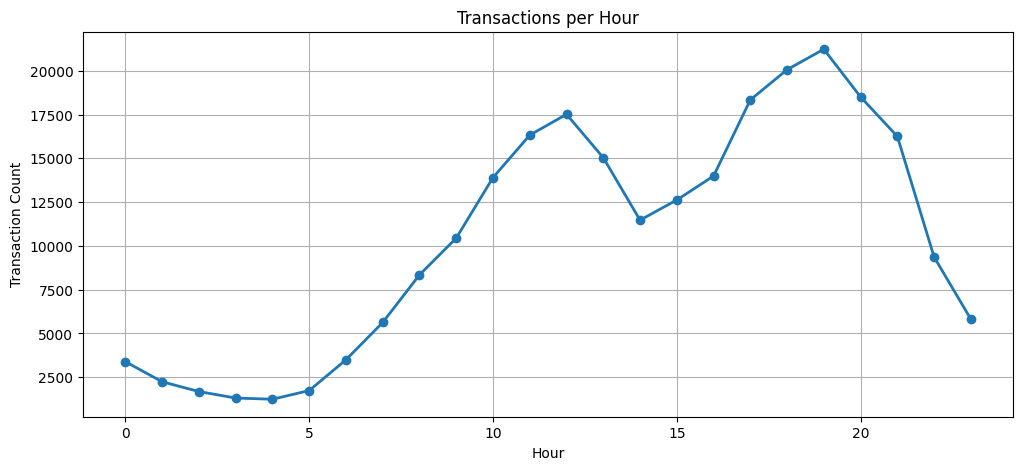

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

transaction_by_hour.plot(
    kind='line',
    marker='o',
    linewidth=2
)

plt.title("Transactions per Hour")
plt.xlabel("Hour")
plt.ylabel("Transaction Count")
plt.grid(True)

plt.show()

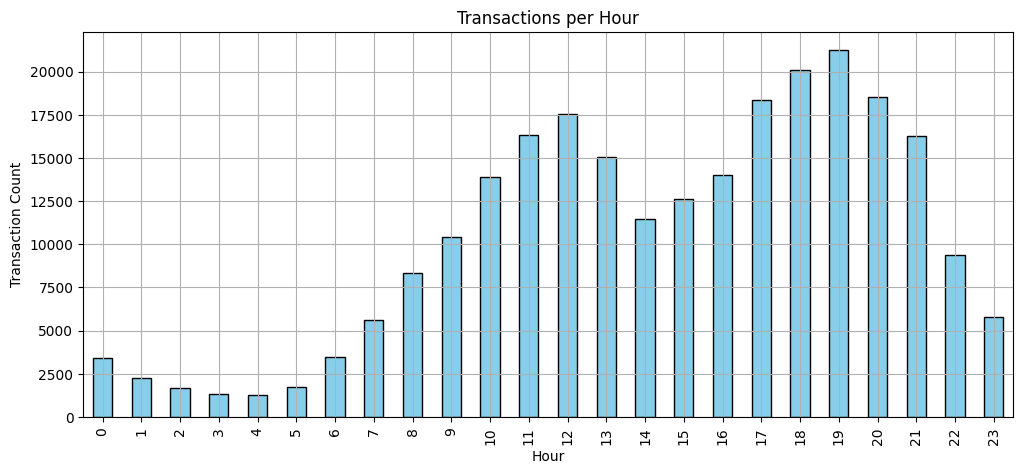

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

transaction_by_hour.plot(
    kind='bar',
    color='skyblue',
    edgecolor='black'
)

plt.title("Transactions per Hour")
plt.xlabel("Hour")
plt.ylabel("Transaction Count")
plt.grid(True)

plt.show()

Transaction by Month

In [45]:
df.index.hour

Index([15,  6, 13, 10, 19, 22, 10, 18,  9, 15,
       ...
       18, 16, 19, 14, 17, 22,  2, 16, 13, 15],
      dtype='int32', name='transaction_date', length=250000)

In [46]:
transaction_by_month = df.groupby(df.index.month)["amount (INR)"].count()

In [47]:
transaction_by_month

transaction_date
1     21221
2     19759
3     21234
4     20536
5     21333
6     20628
7     21207
8     21231
9     20597
10    21252
11    20366
12    20636
Name: amount (INR), dtype: int64

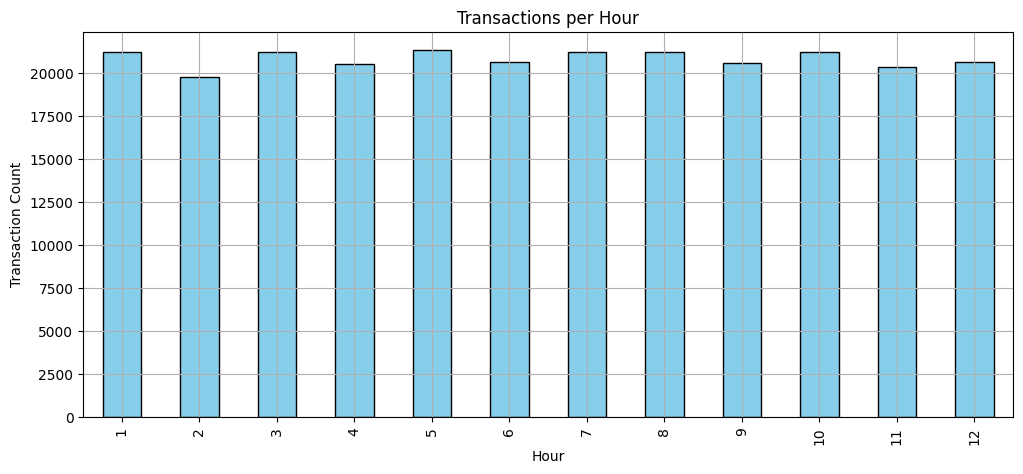

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

transaction_by_month.plot(
    kind='bar',
    color='skyblue',
    edgecolor='black'
)

plt.title("Transactions per Hour")
plt.xlabel("Hour")
plt.ylabel("Transaction Count")
plt.grid(True)

plt.show()